# Хеш-таблицы

> Учебный конспект. Содержание лекции и примеры сохранены.

**Навигация:** [обзор темы](../README.md) · [общий каталог теории](../../docs/theory/README.md)

---


# Хеш-таблицы

После пары вы сможете:

- объяснить, почему словарь на хеше даёт среднее **O(1)** при хорошем разбросе ключей;
- отличить хорошую хеш-функцию от плохой;
- реализовать **метод цепочек** и **открытую адресацию** (`put` / `get` / `remove`);
- объяснить коэффициент заполнения и зачем нужно **рехеширование**.

## План пары (~90 минут)

1. От списка и дерева к константе
2. Пространство признаков и прямая адресация (`m = 100`)
3. Хеш-функции: хорошие и плохие
4. Коллизии: почему неизбежны
5. Метод цепочек
6. Открытая адресация
7. Коэффициент заполнения и рехеширование
8. Сводка «что выбрать»


## Перед началом

**Слова, которые встретятся.**

- **Ключ / значение.** Пара «по чему ищем» → «что храним».
- **Хеш-функция** $h$. Детерминированно превращает ключ в индекс корзины.
- **Корзина (слот).** Ячейка массива таблицы.
- **Коллизия.** Два разных ключа попали в один индекс.
- **Коэффициент заполнения** $\alpha = n/m$. Сколько элементов на одну корзину в среднем.
- **Что верно на каждом шаге.** После операции таблица по-прежнему отвечает на `get` правильно.

**Как пробовать свои числа.** Запустите ячейку ниже. Дальше под сюжетами можно подставлять свои ключи.

[Youtube](https://www.youtube.com/watch?v=btT4bCOvqjs)


In [ ]:
def read_numbers(text: str) -> list[int]:
    """Превращает строку «15, 22 8» в список [15, 22, 8]."""
    return [int(part) for part in text.replace(",", " ").split() if part]


try:
    import ipywidgets as widgets
    from IPython.display import display

    keys_box = widgets.Text(
        value="15 22 8 29 11",
        description="ключи:",
        layout=widgets.Layout(width="70%"),
    )
    display(keys_box)

    def current_keys() -> list[int]:
        return read_numbers(keys_box.value)
except Exception:
    def current_keys() -> list[int]:
        raw = input("ключи через пробел [15 22 8 29 11]: ").strip() or "15 22 8 29 11"
        return read_numbers(raw)


Text(value='15 22 8 29 11', description='ключи:', layout=Layout(width='70%'))

## 1. От списка и дерева к константе

**Идея.** Три способа хранить пары ключ→значение:

| Структура | Поиск | Память / порядок |
| --- | --- | --- |
| Список / массив без сортировки | $O(n)$ | просто |
| Дерево поиска (темы 6–7) | $O(\log n)$ в среднем / при балансе | ключи упорядочены |
| Хеш-таблица | среднее $O(1)$ | порядок ключей сам по себе не обещан |

Хеш не «магия быстрее логарифма всегда»: в худшем случае (все ключи в одной корзине) снова $O(n)$. Среднее $O(1)$ держится, пока хеш-функция хорошо размазывает ключи и таблица не переполнена.


## 2. Пространство признаков и прямая адресация

**Идея.** Выделяем массив из $m$ слотов — «пространство признаков». Функция $h(k)$ указывает **номер слота**. Для целых удобный учебный пример:

`h(k) = k % 100`

— массив длины 100 (в Python оператор `%`).

**Что верно на каждом шаге.** Ключ $k$ всегда попадает в один и тот же слот $h(k)$. Поиск — переход по индексу, без просмотра всех 100 ячеек «наугад».

**Автор и год.** Идея хеширования в программировании — 1950-е (Luhn, Dumey и др.);

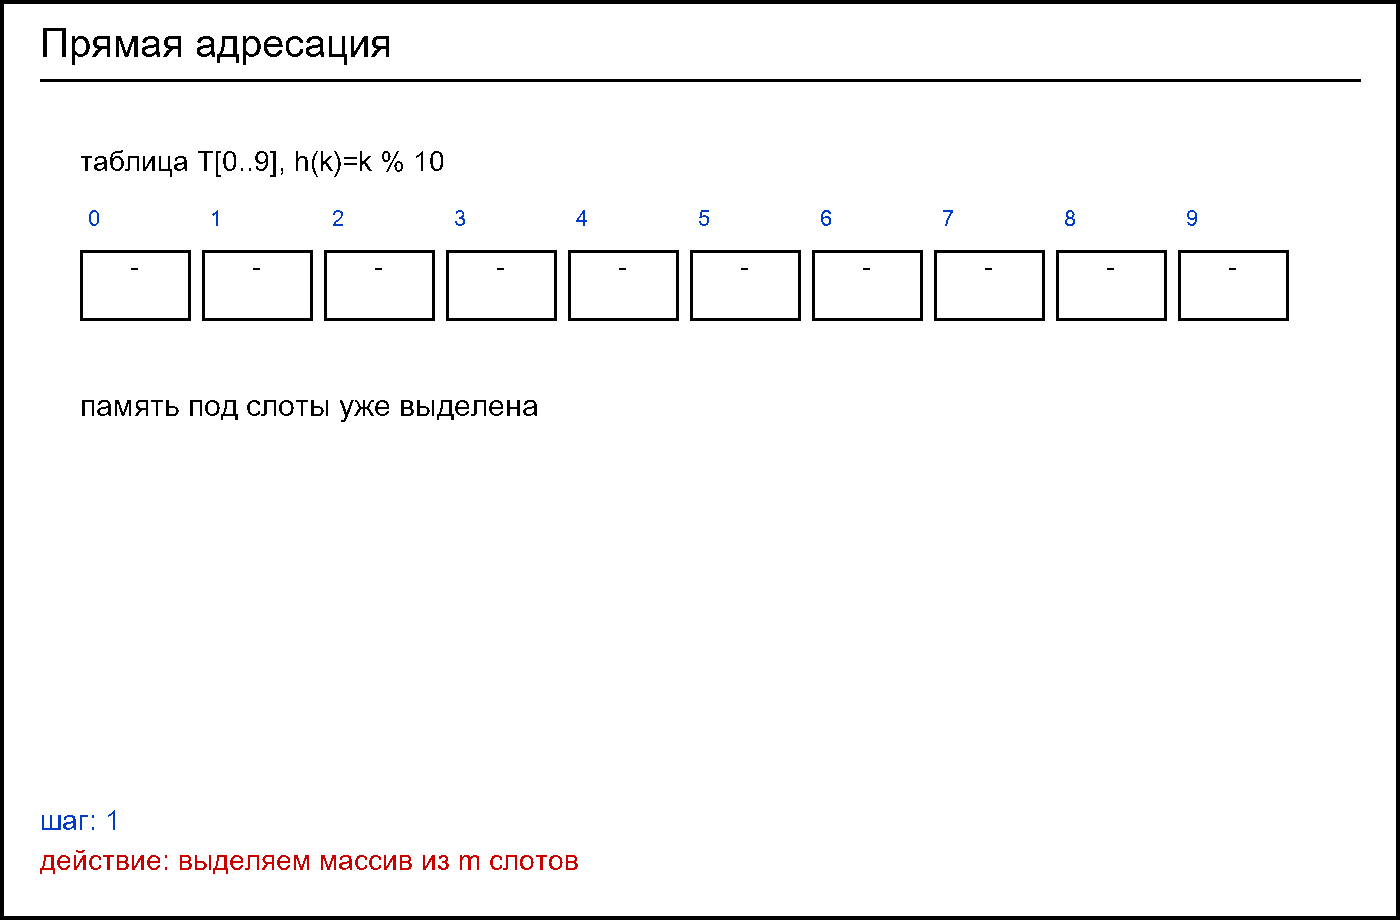



In [ ]:
def demo_direct_addressing(keys: list[int], m: int = 10) -> None:
    table: list[int | None] = [None] * m
    print(f"выделили массив из {m} слотов")
    for k in keys:
        i = k % m
        print(f"ключ {k}: h={k}%{m}={i} → пишем в слот {i}")
        table[i] = k  # учебный вариант: одно значение на слот
        # Что верно: table[h(k)] хранит k (пока нет коллизии)
    print("таблица:", table)


demo_direct_addressing(current_keys()[:3], m=10)


выделили массив из 10 слотов
ключ 15: h=15%10=5 → пишем в слот 5
ключ 22: h=22%10=2 → пишем в слот 2
ключ 8: h=8%10=8 → пишем в слот 8
таблица: [None, None, 22, None, None, 15, None, None, 8, None]


**Оценка сложности.**
  - При отсутствии коллизий `put`/`get` — \(O(1)\).
  - Память —\(O(n)\).



**Пограничные случаи.**
- Два ключа с одним значением на выходе хеш функции — прямая запись затирает соседа. Это и есть коллизия.


## 3. Хеш-функции: хорошие и плохие

**Идея.** Давайте попробуем подобрать такую функцию, которая соответствует критериям:

1. **Детерминированность** — один ключ всегда даёт один адрес в пространстве признаков. Т.е. применение функции к одним и тем же входным параметрам получаем один и тот же результат
2. **Равномерность** — близкие по смыслу ключи не сваливаются в одно значение и распределяются по пространству доступных признаков
3. **Быстрый расчёт** — сама $h$ не должна считаться дольше непосредственного поиска

### Антипример для строк

- В качестве ключей используем строки
- В качестве функции хеша -  «длина строки по модулю $m$». На Python это выглядит так:


In [ ]:
from typing import Hashable
def hash_length(s: str, m: int) -> int:
    return len(s) % m

m = 7
words = ["кот", "ток", "кит", "дом"]  # у всех длина 3
print("плохой хеш: len(s) % m")
for w in words:
    print(f"  {w!r:6}  len={len(w)}  →  слот {hash_length(w, m)}")
print("все строки одной длины попали в одну корзину")


плохой хеш: len(s) % m
  'кот'   len=3  →  слот 3
  'ток'   len=3  →  слот 3
  'кит'   len=3  →  слот 3
  'дом'   len=3  →  слот 3
все строки одной длины попали в одну корзину


In [ ]:
"".join([str(ord(item)) for item in "кот"])

'108210861090'

Для таблицы это плохо: четыре разных ключа делят один слот, остальные пустуют.

### Лучше: учебный полиномиальный хеш

Учитываем символы, а не только длину:

$$
h(s) = \Bigl(\sum_{i=0}^{|s|-1} s[i]\cdot p^{i}\Bigr) \bmod m
$$

В коде $p = 31$, $s[i]$ — код символа (`ord`).


In [ ]:
def hash_length(s: str, m: int) -> int:
    return len(s) % m


def hash_poly(s: str, m: int, p: int = 31) -> int:
    h = 0
    power = 1
    for ch in s:
        h = (h + ord(ch) * power) % m
        power = (power * p) % m
    return h


m = 7
words = ["кот", "ток", "кит", "дом", "собака", "лампа"]
print("сравнение:")
print(f"{'слово':8}  {'len%m':>6}  {'poly':>6}")
for w in words:
    print(f"{w!r:8}  {hash_length(w, m):6d}  {hash_poly(w, m):6d}")


сравнение:
слово      len%m    poly
'кот'          3       3
'ток'          3       2
'кит'          3       6
'дом'          3       6
'собака'       6       3
'лампа'        5       1


## 4. Коллизии: почему неизбежны

**Проблема** Коллизия - случай, когда два разных ключа попали в один слот: $h(k_1)=h(k_2)$, но $k_1 \neq k_2$.

### Почему они всегда будут?

Пусть $U$ — множество всех возможных ключей, $m$ — число слотов, $h\colon U \to \{0,1,\ldots,m-1\}$.

**Принцип Дирихле .** Если голубей больше, чем клеток, в какой-то клетке сидят как минимум двое.

Здесь «голуби» — ключи, «клетки» — значения хеша. Если $|U| > m$, то **не существует** такой $h$, при которой у всех ключей разные индексы: иначе получилось бы $|U|$ различных чисел в диапазоне длины $m$ — невозможно.

**Маленький пример.** $m = 3$ слота, ключи из $\{0,1,2,3,4\}$ (уже 5 штук).  
Любая $h$ выдаёт только $0$, $1$ или $2$. Среди пяти ключей хотя бы два обязаны дать один и тот же остаток — это и есть коллизия.

**Итого:** Хорошая хеш-функция не исключает коллизий, но старается минимизировать шанс их появления. Она обещает, что при $n$ вставленных ключах и разумном $m$ коллизии **редки в среднем**. Поэтому нужны методы разрешения таких ситуаций

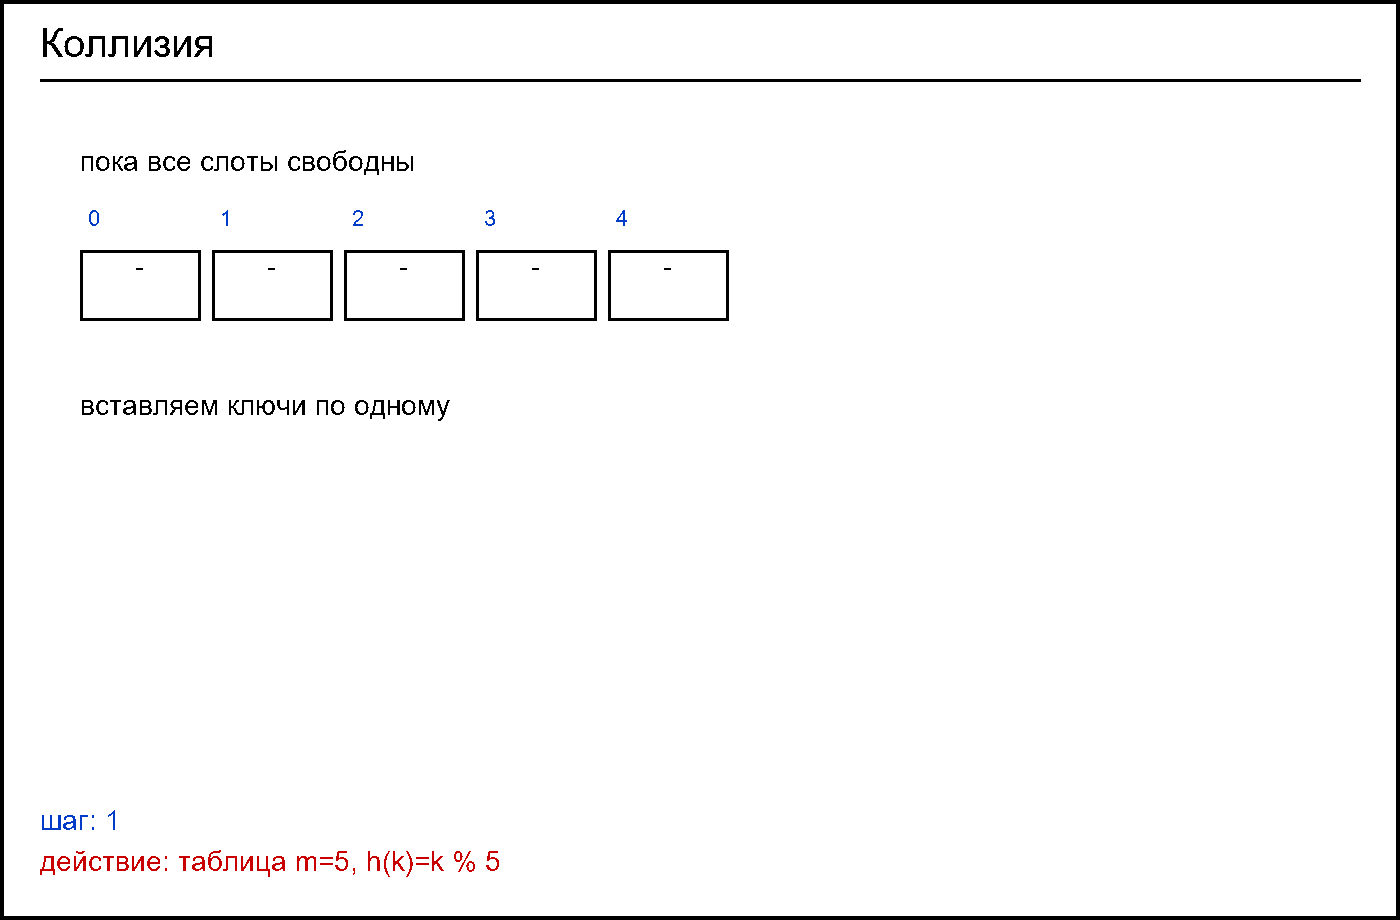



## 5. Метод цепочек

**Идея.**
- При возникновении коллизии, просто создаем "цепочку" в ячейке значения
- Новая коллизия вызывает добавление пары ключ-значение в конец "цепочки"

**Что дает:**
- "резиновое" пространство признаков

**Чем жертвуем**
- Сложность стремится от O(1) > O(n)

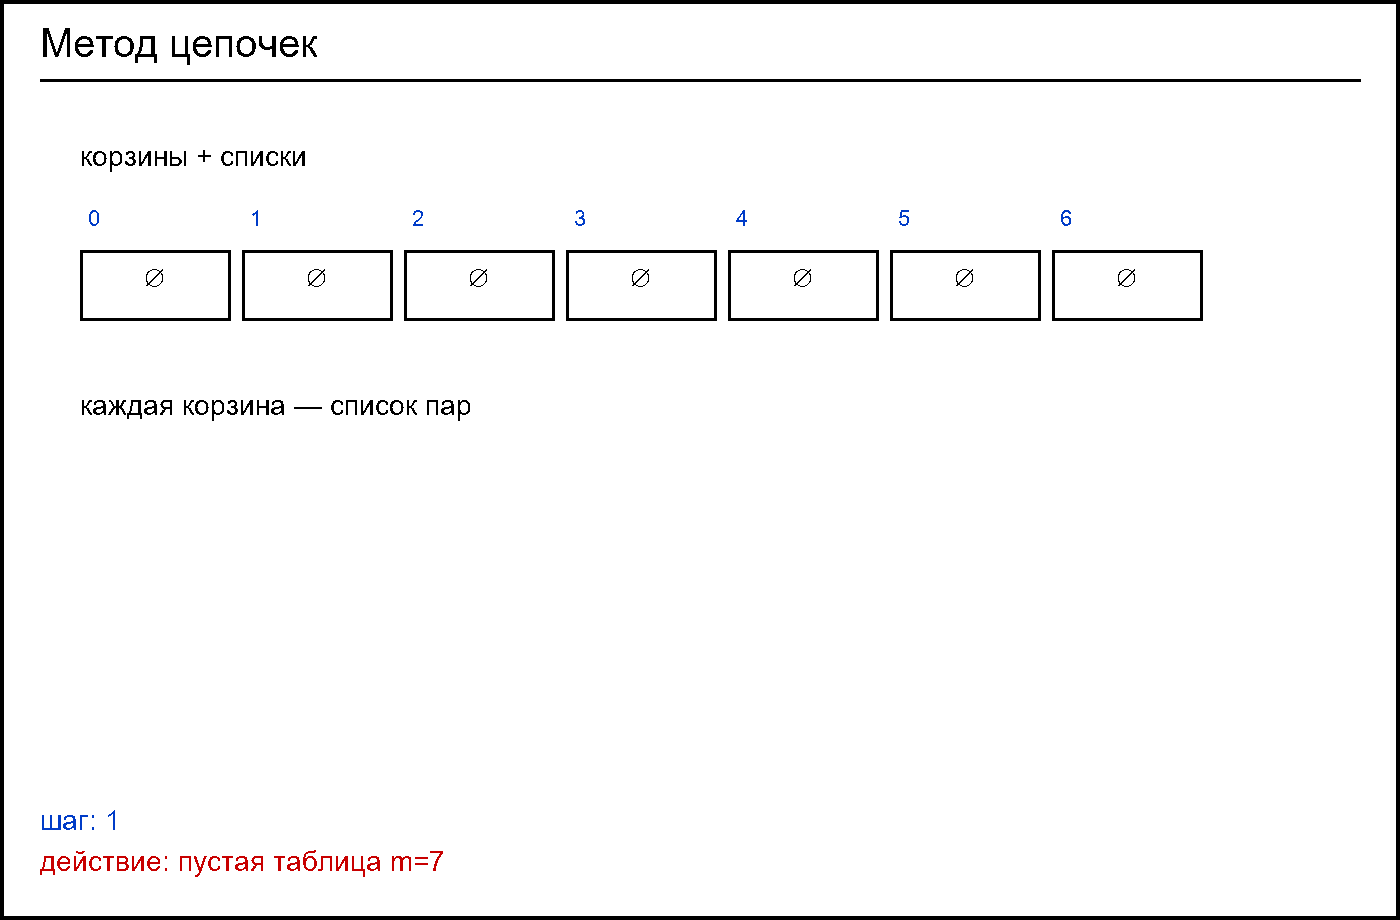


In [ ]:
class ChainedHashMap:
    """Хеш-таблица: разрешение коллизий методом цепочек."""

    def __init__(self, capacity: int = 8) -> None:
        self.capacity = capacity
        self.buckets: list[list[tuple[int, object]]] = [[] for _ in range(capacity)]
        self.size = 0

    def _h(self, key: int) -> int:
        return key % self.capacity

    def put(self, key: int, value: object, verbose: bool = True) -> None:
        i = self._h(key)
        bucket = self.buckets[i]
        for j, (k, _) in enumerate(bucket):
            if k == key:
                if verbose:
                    print(f"put {key}: обновляем в корзине {i}")
                bucket[j] = (key, value)
                return
        bucket.append((key, value))
        self.size += 1
        if verbose:
            print(f"put {key}: корзина {i}, длина цепочки {len(bucket)}")
        # Что верно: ключ key есть ровно в buckets[h(key)]

    def get(self, key: int, verbose: bool = True) -> object | None:
        i = self._h(key)
        for k, v in self.buckets[i]:
            if k == key:
                if verbose:
                    print(f"get {key}: нашли в корзине {i}")
                return v
        if verbose:
            print(f"get {key}: нет в корзине {i}")
        return None

    def remove(self, key: int, verbose: bool = True) -> bool:
        i = self._h(key)
        bucket = self.buckets[i]
        for j, (k, _) in enumerate(bucket):
            if k == key:
                bucket.pop(j)
                self.size -= 1
                if verbose:
                    print(f"remove {key}: удалили из корзины {i}")
                return True
        if verbose:
            print(f"remove {key}: не было")
        return False


chained = ChainedHashMap(capacity=7)
for k in current_keys():
    chained.put(k, f"v{k}")
print("get 29 →", chained.get(29))
chained.remove(22)
print("корзины:", chained.buckets)


put 15: корзина 1, длина цепочки 1
put 22: корзина 1, длина цепочки 2
put 8: корзина 1, длина цепочки 3
put 29: корзина 1, длина цепочки 4
put 11: корзина 4, длина цепочки 1
get 29: нашли в корзине 1
get 29 → v29
remove 22: удалили из корзины 1
корзины: [[], [(15, 'v15'), (8, 'v8'), (29, 'v29')], [], [], [(11, 'v11')], [], []]


## 6. Открытая адресация

**Идея.**
- Если ячейка с индексом h(k) занята — ищем другую свободную ячейку по некоторому правилу.
- Правило поиска называется пробированием (probing, от англ. probe — «зонд», «проба»).
- Формально: есть последовательность проб h(k, 0), h(k, 1), h(k, 2), h(k, i) индекс на i-й попытке.
- Мы идём по этой последовательности, пока не найдём свободную ячейку (при вставке) или нужный ключ (при поиске).


**Удаление.**
- При удалении не обнуляем ячейку, а ставим специальную метку DELETED - tombstone (надгробие).
- При вставке можно переиспользовать надгробие: если встретили DELETED до того, как нашли пустую ячейку — запоминаем её как кандидата и продолжаем искать настоящую пустую. Если ключа в таблице нет — вставляем в первую встреченную DELETED. Это нужно, чтобы не создавать дубликаты.


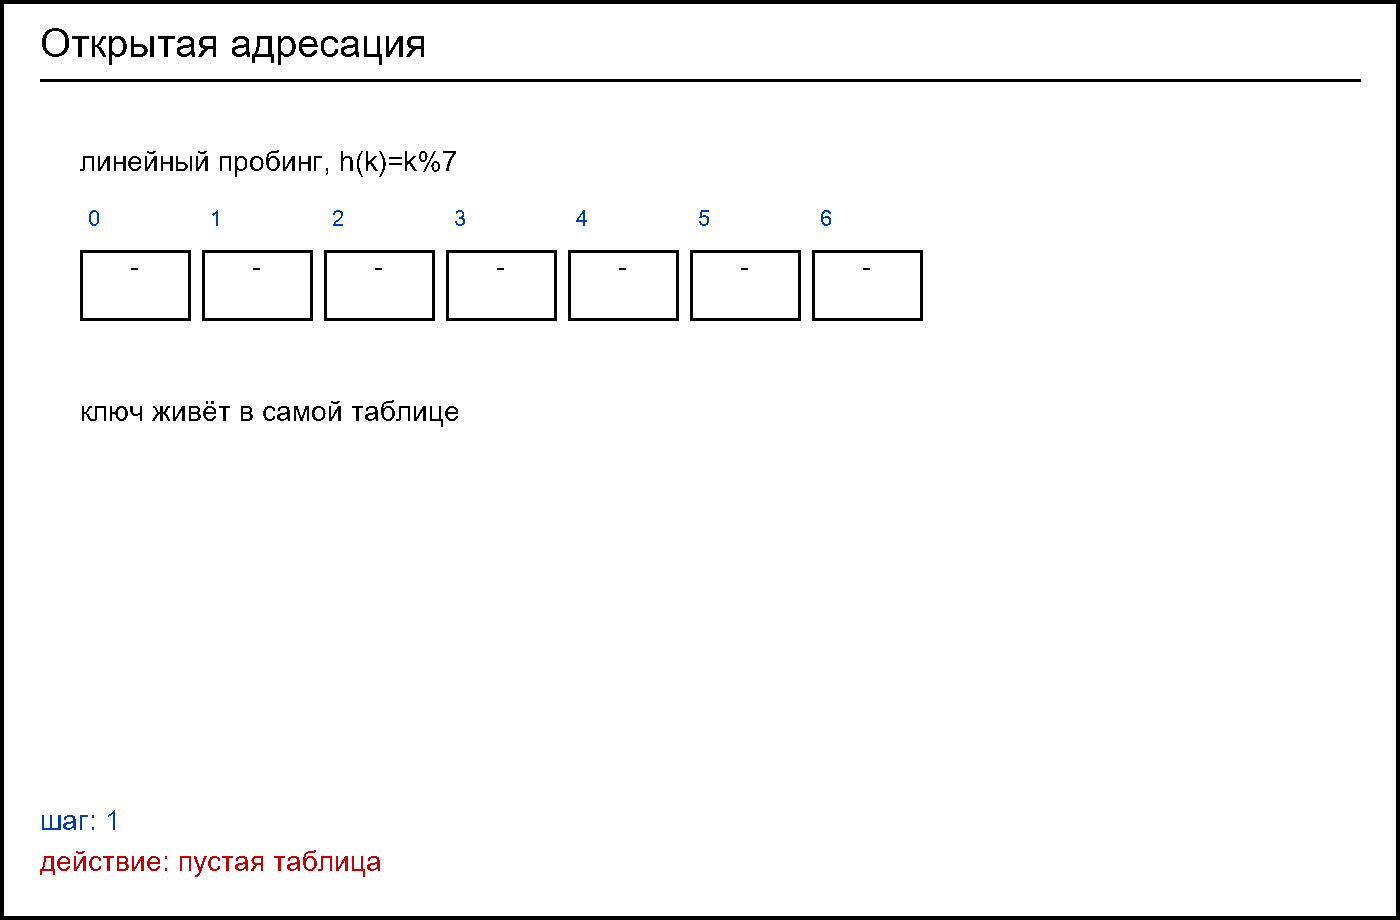


In [ ]:
_TOMB = object()  # надгробие


class OpenHashMap:
    """Хеш-таблица: открытая адресация, линейный пробинг."""

    def __init__(self, capacity: int = 8) -> None:
        assert capacity > 0
        self.capacity = capacity
        # None — пусто; _TOMB — удалено; (key, value) — занято
        self.slots: list = [None] * capacity
        self.size = 0  # число живых пар (без надгробий)

    def _h(self, key: int) -> int:
        return key % self.capacity

    def put(self, key: int, value: object, verbose: bool = True) -> None:
        first_tomb = None
        for j in range(self.capacity):
            i = (self._h(key) + j) % self.capacity
            cell = self.slots[i]
            if cell is None:
                dest = first_tomb if first_tomb is not None else i
                self.slots[dest] = (key, value)
                self.size += 1
                if verbose:
                    print(f"put {key}: слот {dest} (проб {j+1})")
                return
            if cell is _TOMB:
                if first_tomb is None:
                    first_tomb = i
                continue
            k, _ = cell
            if k == key:
                self.slots[i] = (key, value)
                if verbose:
                    print(f"put {key}: обновили слот {i}")
                return
        raise RuntimeError("таблица полна")

    def get(self, key: int, verbose: bool = True) -> object | None:
        for j in range(self.capacity):
            i = (self._h(key) + j) % self.capacity
            cell = self.slots[i]
            if cell is None:
                if verbose:
                    print(f"get {key}: пустой слот {i}, нет")
                return None
            if cell is _TOMB:
                continue
            k, v = cell
            if k == key:
                if verbose:
                    print(f"get {key}: слот {i}")
                return v
        return None

    def remove(self, key: int, verbose: bool = True) -> bool:
        for j in range(self.capacity):
            i = (self._h(key) + j) % self.capacity
            cell = self.slots[i]
            if cell is None:
                if verbose:
                    print(f"remove {key}: не найден")
                return False
            if cell is _TOMB:
                continue
            k, _ = cell
            if k == key:
                self.slots[i] = _TOMB
                self.size -= 1
                if verbose:
                    print(f"remove {key}: надгробие в слоте {i}")
                return True
        return False


open_map = OpenHashMap(capacity=7)
for k in current_keys():
    open_map.put(k, f"v{k}")
print("slots:", [None if c is None else ("T" if c is _TOMB else c) for c in open_map.slots])
print("get 8 →", open_map.get(8))
open_map.remove(22)
print("после remove 22:", [None if c is None else ("T" if c is _TOMB else c) for c in open_map.slots])
open_map.remove(8)
print("после remove 8:", [None if c is None else ("T" if c is _TOMB else c) for c in open_map.slots])


put 15: слот 1 (проб 1)
put 22: слот 2 (проб 2)
put 8: слот 3 (проб 3)
put 29: слот 4 (проб 4)
put 11: слот 5 (проб 2)
slots: [None, (15, 'v15'), (22, 'v22'), (8, 'v8'), (29, 'v29'), (11, 'v11'), None]
get 8: слот 3
get 8 → v8
remove 22: надгробие в слоте 2
после remove 22: [None, (15, 'v15'), 'T', (8, 'v8'), (29, 'v29'), (11, 'v11'), None]
remove 8: надгробие в слоте 3
после remove 8: [None, (15, 'v15'), 'T', 'T', (29, 'v29'), (11, 'v11'), None]


**Плюсы.**
- Данные компактнее (нет списков) и все ключи живут в том же пространстве признаков;

**Минусы.**
- проблемы кластеризации при линейном пробинге;
- Сложное удаление сложнее (надгробия).

**Сложность.**
- Худший случай — \(O(n)\).


## 7. Коэффициент заполнения и рехеширование

**Идея.** $\alpha = n / m$. Пока $\alpha$ ограничен константой, среднее время операций — $O(1)$. На практике порог около $0.5 \dots 0.75$: превысили — выделяем больший массив (часто $2m$) и **вставляем все ключи заново** с новым $h$.

**Начальная ёмкость.**
- Слишком маленькая → частые рехеши;
- слишком большая → лишняя память.
- Если знаете порядок $n$ заранее — задайте $m \approx n / \alpha$, где $\alpha$ — $\alpha$ — желаемый коэффициент заполнения (например $0.7$).

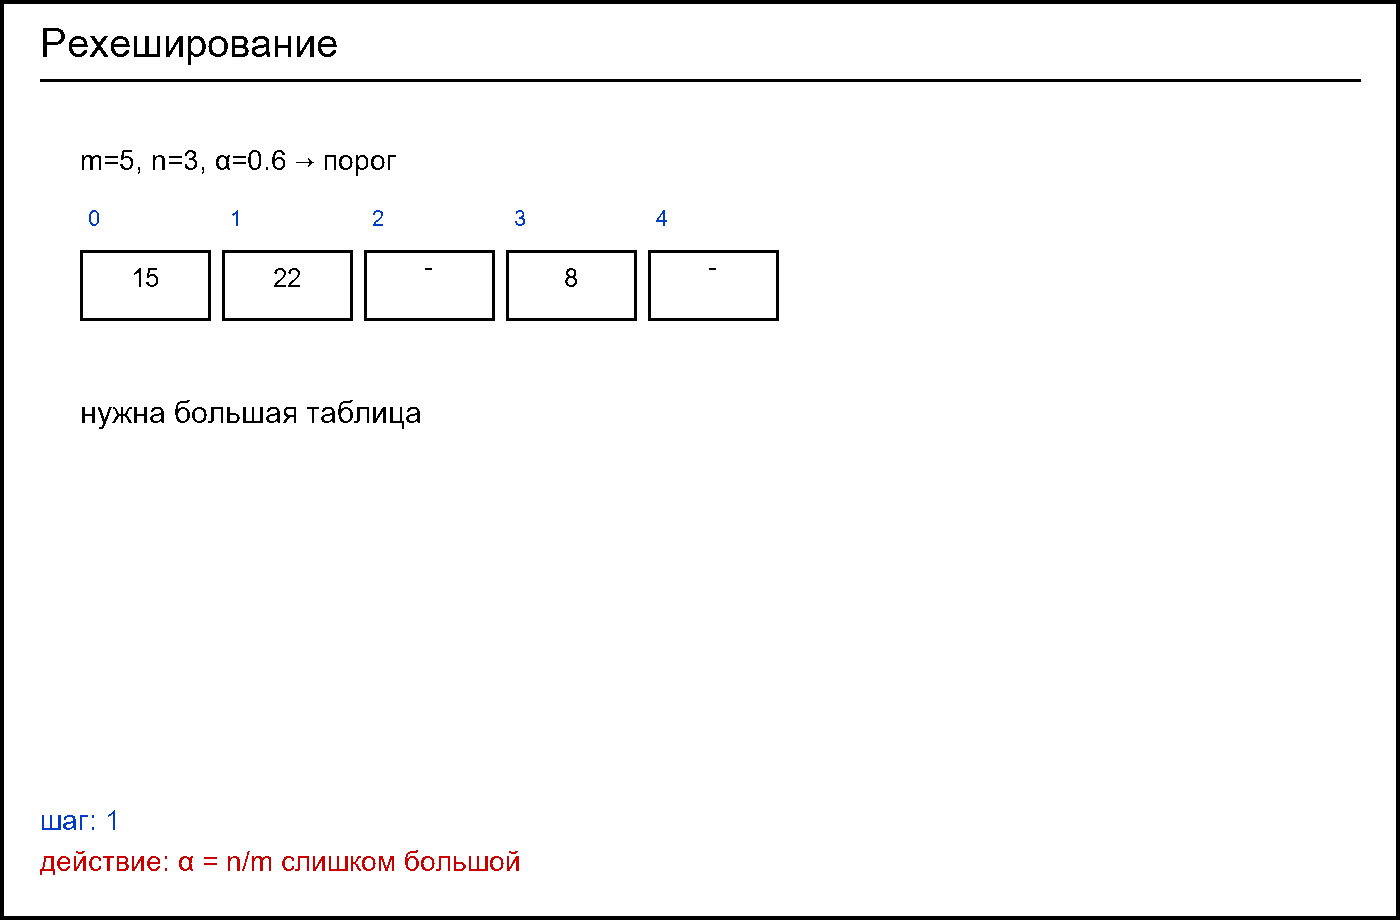


In [ ]:
class GrowingOpenHashMap(OpenHashMap):
    """OpenHashMap с рехешированием при alpha > threshold."""

    def __init__(self, capacity: int = 4, threshold: float = 0.7) -> None:
        super().__init__(capacity=capacity)
        self.threshold = threshold

    @property
    def load_factor(self) -> float:
        return self.size / self.capacity

    def _rehash(self, verbose: bool = True) -> None:
        old = [c for c in self.slots if c is not None and c is not _TOMB]
        new_cap = self.capacity * 2
        if verbose:
            print(f"rehash: {self.capacity} → {new_cap}, переносим {len(old)} ключей")
        self.capacity = new_cap
        self.slots = [None] * new_cap
        self.size = 0
        for k, v in old:
            super().put(k, v, verbose=False)

    def put(self, key: int, value: object, verbose: bool = True) -> None:
        # обновление существующего ключа не увеличивает size до проверки —
        # упрощённо: рехеш до вставки, если уже тесно
        if self.load_factor > self.threshold:
            self._rehash(verbose=verbose)
        super().put(key, value, verbose=verbose)


grow = GrowingOpenHashMap(capacity=4, threshold=0.7)
for k in [10, 20, 30, 40, 50]:
    print(f"--- put {k}, alpha до = {grow.load_factor:.2f}")
    grow.put(k, k)
print("итог capacity", grow.capacity, "size", grow.size, "alpha", round(grow.load_factor, 2))


--- put 10, alpha до = 0.00
put 10: слот 2 (проб 1)
--- put 20, alpha до = 0.25
put 20: слот 0 (проб 1)
--- put 30, alpha до = 0.50
put 30: слот 3 (проб 2)
--- put 40, alpha до = 0.75
rehash: 4 → 8, переносим 3 ключей
put 40: слот 0 (проб 1)
--- put 50, alpha до = 0.50
put 50: слот 3 (проб 2)
итог capacity 8 size 5 alpha 0.62


## Сводка: что выбрать

| Задача | Структура |
| --- | --- |
| Нужен порядок ключей / ближайший больший | дерево поиска / сортированный массив |
| Нужен быстрый словарь «ключ → значение» | хеш-таблица (`dict` в Python) |
| Много коллизий допустимы, проще удалять | цепочки |
| Нужна компактность, \(\alpha\) контролируем | открытая адресация |
| Таблица растёт | следите за \(\alpha\), делайте рехеш |

На семинаре: своя `OpenHashMap` с открытой адресацией, затем кэши LRU и MRU+TTL **без** встроенного `dict`.
